# Aftereffect analysis — what is learned under a visual gain of 2?

**Design recap.** Each cycle: **washout** at gain 1 (cursor on, all four targets) → **training** at gain 2 on **one** target (cursor on) → **test** at gain 1 with **no cursor** on all four targets. Targets are index-finger extents of ±2 and ±4 cm (negative = flexion, positive = extension).

Hitting a target at gain 2 takes about half the force, so the aftereffect we look for is a **reduction in force magnitude** at test.

**Aftereffect** (within participant: pool trials first, then subtract, as in `LearningDynamicsAnalysis.ipynb`):

- `AE = mean |F| washout − mean |F| test` (N); positive = less force at test
- `AE % = 100 · AE / mean |F| washout`, the proportional aftereffect

**The story in four questions**

1. **Is the aftereffect local?** Does it stay at the trained target?
2. **Additive or gain?** Does training take a fixed amount of force off (additive) or scale force (multiplicative gain)?
3. **Flexion vs extension.** Does it transfer to the opposite direction (other muscles)? Is that transfer complete (one shared controller) or partial? Is it a magnitude (gain) change or a directional bias?
4. **Robustness.** The aftereffect decays during the no-cursor test block. Do the conclusions hold in early test trials?

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import utils
import seaborn as sns
from pathlib import Path
import scipy.stats as stats
from matplotlib.colors import to_rgb
from matplotlib.lines import Line2D

path_figs = "./Figs/"
Path(path_figs).mkdir(parents=True, exist_ok=True)

conditions = utils.conditions
epoch_order = ['washout', 'adaptation', 'test']
epoch_labels = {'washout': 'Washout', 'adaptation': 'Training', 'test': 'Test'}

# Test trials (per target) counted in the aftereffect; 15 = whole test block
n_test_trials = 15
# Early-test window for the robustness check (Section 4)
n_early_trials = 5

# Fill in after collection, or leave None to keep every subject in subjs.csv
sub_nums = None

n_boot = 5000
rng = np.random.default_rng(0)

utils.set_figure_style("1col")


def with_opacity(color, alpha, background=(1, 1, 1)):
    """Simulate alpha by blending toward the background (seaborn ignores RGBA alpha)."""
    c = np.asarray(to_rgb(color))
    bg = np.asarray(background)
    return tuple(alpha * c + (1 - alpha) * bg)


cb = sns.color_palette('colorblind')
# Flexion (negative) → colorblind[0]; extension (positive) → colorblind[3]
# Larger |target| → higher opacity
condition_palette = {
    -4: with_opacity(cb[0], 1.0),
    -2: with_opacity(cb[0], 0.45),
     2: with_opacity(cb[3], 0.45),
     4: with_opacity(cb[3], 1.0),
}
direction_palette = {'Flexion': cb[0], 'Extension': cb[3]}
extent_palette = {2: '0.6', 4: 'black'}  # direction pooled: 2 cm lighter, 4 cm darker


def report_ttest(label, result):
    print(f"{label}: p-value: {result.pvalue:.4f}, t-stat: {result.statistic:.2f}, df: {result.df}")

## Data loading

Same loading as `LearningDynamicsAnalysis.ipynb`. `prepare_aftereffect_trials` keeps washout trials plus the first `n` test trials per target, and labels how each test target relates to the trained target.

In [2]:
subjs_path = utils.path_misc + 'subjs.csv'
if not Path(subjs_path).exists():
    raise FileNotFoundError(
        f"{subjs_path} not found. Run DatPreProcessing.ipynb after .dat files are copied in."
    )

subjs = pd.read_csv(subjs_path, sep='\t')
if sub_nums is not None:
    subjs = subjs[subjs['subNum'].isin(sub_nums)].reset_index(drop=True)

subjs_correct = utils.remove_error_trials(subjs).copy()
subjs_correct['epoch'] = pd.Categorical(
    subjs_correct['block_type'].map(epoch_labels),
    categories=[epoch_labels[e] for e in epoch_order],
    ordered=True,
)


def prepare_aftereffect_trials(data, n_test):
    """Washout + first `n_test` test trials per target, with |F| and train/test relation labels."""
    df = data.loc[
        (data['epoch'] == 'Washout')
        | ((data['epoch'] == 'Test') & (data['trial_num_within_condition'] <= n_test))
    ].copy()
    df['force_magnitude'] = df['producedForce2'].abs()
    df['train_extent'] = df['adaptation_condition'].abs().astype(int)  # 2 or 4
    df['test_extent'] = df['condition'].abs().astype(int)
    df['train_direction'] = np.where(df['adaptation_condition'] < 0, 'Flexion', 'Extension')
    df['test_direction'] = np.where(df['condition'] < 0, 'Flexion', 'Extension')
    df['direction_match'] = np.where(
        df['train_direction'] == df['test_direction'], 'Trained direction', 'Opposite direction'
    )
    df['extent_match'] = np.where(
        df['train_extent'] == df['test_extent'], 'Trained extent', 'Other extent'
    )
    df['generalization'] = np.where(
        df['direction_match'] == 'Opposite direction',
        'Opposite direction',
        np.where(df['extent_match'] == 'Trained extent', 'Trained target', 'Other extent'),
    )
    return df


def pooled_aftereffect(df, keys):
    """Within participant × keys: pool trials, then AE = washout |F| − test |F|."""
    pooled = (
        df.groupby(['subNum', *keys, 'epoch'], observed=True)['force_magnitude']
        .mean()
        .unstack('epoch')
    )
    pooled['AE'] = pooled['Washout'] - pooled['Test']
    pooled['AE_percent'] = 100 * pooled['AE'] / pooled['Washout']
    return pooled.reset_index()


ae_trials = prepare_aftereffect_trials(subjs_correct, n_test_trials)
n_subj = ae_trials['subNum'].nunique()
print(f"{n_subj} participants; test trials per target: {n_test_trials}")

8 participants; test trials per target: 15


## 0. Hypotheses and predictions

Idealized predictions in arbitrary units.

**Extent (test in the trained direction).** x = test extent; lines = trained extent.

| Model | What is learned | Prediction |
|---|---|---|
| Local | a change tied to the trained target | AE only at the trained extent |
| Additive | a fixed reduction of force (N) | same AE at 2 and 4 cm, whichever extent was trained |
| Gain | a scaling of force | AE ∝ baseline force: larger at 4 cm for both trained extents |
| Gain + local | scaling plus an extra reduction at the trained target | trained on 2 cm the two cancel (≈ flat); trained on 4 cm they add (steep) |

The gain prediction uses the **measured** washout forces, not the nominal extents. Participants compress their forces (Panel 2A), so the predicted 4 cm / 2 cm ratio is below 2.

**Direction (trained vs opposite direction).**

| Model | What is learned | Opposite-direction AE |
|---|---|---|
| Separate controllers | flexors and extensors adapt independently | 0 |
| Shared gain | one magnitude gain for both directions | = trained-direction AE |
| Partially shared | part of the gain generalizes | between 0 and the trained-direction AE |
| Directional bias | a signed shift: "less flexion" = "more extension" | **negative** (more force in the opposite direction) |

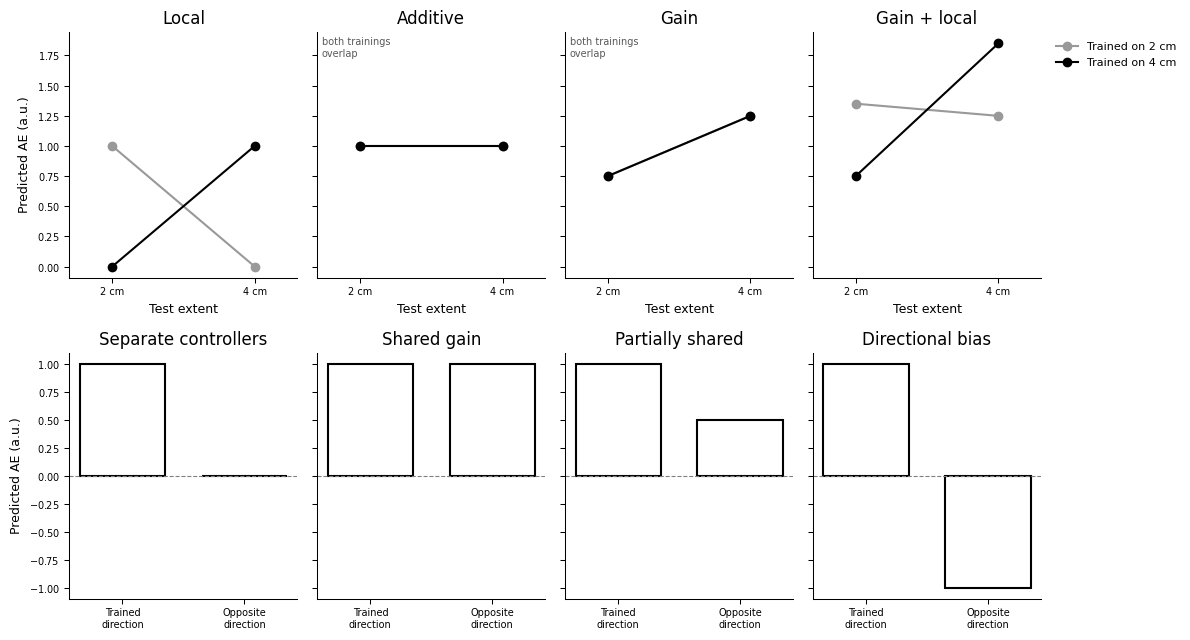

In [3]:
# --- Fig 0: idealized predictions (arbitrary units) ---
washout_by_extent = (
    ae_trials.loc[ae_trials['epoch'] == 'Washout']
    .groupby(['subNum', 'test_extent'])['force_magnitude'].mean()
    .groupby('test_extent').mean()
)
gain_scale = washout_by_extent / washout_by_extent.mean()  # measured washout ratio
local_bump = 0.6

extent_models = {
    'Local': {2: [1.0, 0.0], 4: [0.0, 1.0]},
    'Additive': {2: [1.0, 1.0], 4: [1.0, 1.0]},
    'Gain': {2: [gain_scale[2], gain_scale[4]], 4: [gain_scale[2], gain_scale[4]]},
    'Gain + local': {
        2: [gain_scale[2] + local_bump, gain_scale[4]],
        4: [gain_scale[2], gain_scale[4] + local_bump],
    },
}
direction_models = {
    'Separate controllers': [1.0, 0.0],
    'Shared gain': [1.0, 1.0],
    'Partially shared': [1.0, 0.5],
    'Directional bias': [1.0, -1.0],
}

fig, axs = plt.subplots(2, 4, figsize=(12, 6.5), sharey='row')

for ax, (name, pred) in zip(axs[0], extent_models.items()):
    for train_ext in [2, 4]:
        ax.plot([2, 4], pred[train_ext], marker='o', color=extent_palette[train_ext],
                label=f'Trained on {train_ext} cm')
    if pred[2] == pred[4]:
        ax.annotate('both trainings\noverlap', xy=(0.02, 0.98), xycoords='axes fraction',
                    va='top', ha='left', fontsize=7, color='0.35')
    ax.set_title(name)
    ax.set_xticks([2, 4])
    ax.set_xticklabels(['2 cm', '4 cm'])
    ax.set_xlim(1.4, 4.6)
    ax.set_xlabel('Test extent')
axs[0, 0].set_ylabel('Predicted AE (a.u.)')
axs[0, -1].legend(frameon=False, bbox_to_anchor=(1.02, 1), loc='upper left')

for ax, (name, pred) in zip(axs[1], direction_models.items()):
    ax.bar([0, 1], pred, width=0.7, fill=False, edgecolor='black', linewidth=1.5)
    ax.axhline(0, color='gray', linestyle='--', linewidth=0.8)
    ax.set_title(name)
    ax.set_xticks([0, 1])
    ax.set_xticklabels(['Trained\ndirection', 'Opposite\ndirection'])
axs[1, 0].set_ylabel('Predicted AE (a.u.)')

sns.despine()
plt.tight_layout()
plt.savefig(path_figs + 'ae_fig0_predictions.pdf', bbox_inches='tight')
plt.show()

## 1. Is the aftereffect local?

Test targets grouped by their relation to the trained target:

- **Trained target:** same direction, same extent
- **Other extent:** same direction, the other extent
- **Opposite direction:** both extents of the other direction

**Local:** AE only at the trained target. **Not local:** AE at the other extent as well (and possibly in the opposite direction).

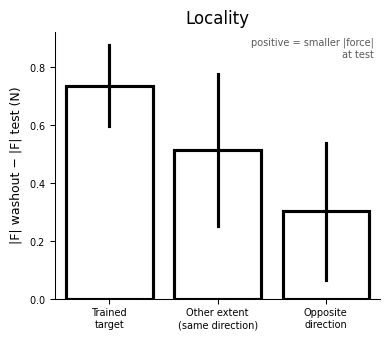

Trained target AE vs 0: p-value: 0.0012, t-stat: 5.26, df: 7
Other extent AE vs 0: p-value: 0.0905, t-stat: 1.96, df: 7
Opposite direction AE vs 0: p-value: 0.2411, t-stat: 1.28, df: 7
Trained target vs other extent: p-value: 0.1727, t-stat: 1.52, df: 7


In [4]:
# --- Fig 1: AE at the trained target vs untrained targets ---
gen_order = ['Trained target', 'Other extent', 'Opposite direction']
fig1_data = pooled_aftereffect(ae_trials, ['generalization'])

fig, ax = plt.subplots(figsize=(4, 3.5))
sns.barplot(
    data=fig1_data,
    x='generalization',
    y='AE',
    order=gen_order,
    errorbar='se',
    ax=ax,
    color='black',
    fill=False,
)
ax.axhline(0, color='gray', linestyle='--', linewidth=0.8)
ax.set_title('Locality')
ax.set_xlabel('')
ax.set_xticks(range(len(gen_order)))
ax.set_xticklabels(['Trained\ntarget', 'Other extent\n(same direction)', 'Opposite\ndirection'])
ax.set_ylabel('|F| washout − |F| test (N)')
ax.annotate(
    'positive = smaller |force|\nat test',
    xy=(0.98, 0.98),
    xycoords='axes fraction',
    va='top',
    ha='right',
    fontsize=7,
    color='0.35',
)

sns.despine()
plt.tight_layout()
plt.savefig(path_figs + 'ae_fig1_locality.pdf', bbox_inches='tight')
plt.show()

fig1_wide = fig1_data.pivot(index='subNum', columns='generalization', values='AE')
for gen in gen_order:
    report_ttest(f"{gen} AE vs 0", stats.ttest_1samp(fig1_wide[gen], 0))
report_ttest(
    "Trained target vs other extent",
    stats.ttest_rel(fig1_wide['Trained target'], fig1_wide['Other extent']),
)

**Reading (n = 8).** The AE is largest at the trained target, but a sizeable part is also there at the **other extent** (≈ 70 % of the trained-target AE) and a smaller part in the **opposite direction**. So the aftereffect is **not fully local**. With the whole test block the other-extent AE is only a trend against 0; it is significant with early test trials (Section 4).

## 2. Additive or gain?

In force units the extent pattern looks like both: trained on 2 cm the AE is flat across extents (additive-like); trained on 4 cm it is larger at 4 cm (gain-like). Four steps resolve this:

- **2A:** The gain prediction should use the force actually produced in washout, not the nominal extent.
- **2B:** Plot AE against washout force. Averaging over the two trained extents cancels any local component, because each test extent is trained once and untrained once. What remains is **flat** under additive and a **line through the origin** under gain.
- **2C:** Proportional AE. Gain predicts equal AE % at both extents; a local component shows up as a crossover.
- **2D:** Fit additive, gain and local components jointly.

This section uses test targets in the trained direction only (flexion and extension pooled via |F|).

### 2A — Washout force is compressed relative to the targets

Dotted lines = nominal target. If participants undershoot 4 cm and overshoot 2 cm, the force ratio between extents is < 2, and so is the AE ratio predicted by gain.

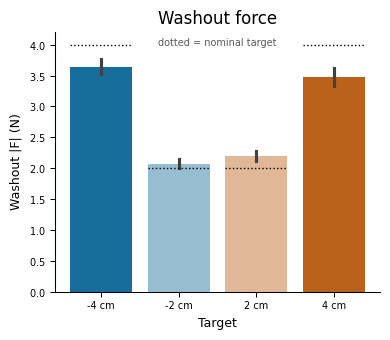

Washout |F| ratio 4 cm / 2 cm: 1.68 ± 0.07 (mean ± SEM); nominal = 2


In [5]:
# --- Fig 2A: washout force vs nominal target ---
washout_subj = (
    ae_trials.loc[ae_trials['epoch'] == 'Washout']
    .groupby(['subNum', 'condition'])['force_magnitude']
    .mean()
    .reset_index()
)
washout_subj['condition'] = washout_subj['condition'].astype(int)

fig, ax = plt.subplots(figsize=(4, 3.5))
sns.barplot(
    data=washout_subj,
    x='condition',
    y='force_magnitude',
    order=conditions,
    hue='condition',
    hue_order=conditions,
    palette=condition_palette,
    errorbar='se',
    legend=False,
    ax=ax,
)
for i, cond in enumerate(conditions):
    ax.hlines(abs(cond), i - 0.4, i + 0.4, colors='black', linestyles=':', linewidth=1.0)
ax.set_xticks(range(len(conditions)))
ax.set_xticklabels([f'{c} cm' for c in conditions])
ax.set_xlabel('Target')
ax.set_ylabel('Washout |F| (N)')
ax.set_title('Washout force')
ax.annotate(
    'dotted = nominal target',
    xy=(0.5, 0.98),
    xycoords='axes fraction',
    va='top',
    ha='center',
    fontsize=7,
    color='0.35',
)

sns.despine()
plt.tight_layout()
plt.savefig(path_figs + 'ae_fig2a_washout_force.pdf', bbox_inches='tight')
plt.show()

washout_wide = (
    washout_subj.assign(extent=washout_subj['condition'].abs())
    .groupby(['subNum', 'extent'])['force_magnitude'].mean()
    .unstack()
)
washout_ratio = washout_wide[4] / washout_wide[2]
print(f"Washout |F| ratio 4 cm / 2 cm: {washout_ratio.mean():.2f} ± {washout_ratio.sem():.2f} (mean ± SEM); nominal = 2")

### 2B — Aftereffect vs washout force

Left: each trained extent separately. Filled markers = test at the trained extent, open = test at the other extent.
Right: averaged over the two trained extents (local component cancelled), with the two one-parameter predictions fitted to these points:

- **Additive:** flat line
- **Gain:** line through the origin

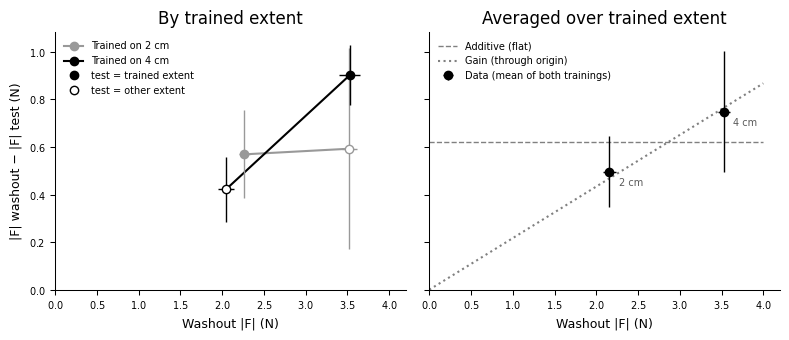

AE ratio 4 cm / 2 cm (averaged over training): 1.51; additive predicts 1.00, gain predicts 1.64
Additive model: RMS error at the two group means = 0.126 N
Gain model: RMS error at the two group means = 0.023 N
AE at 4 cm vs 2 cm (averaged over training): p-value: 0.1273, t-stat: 1.73, df: 7


In [6]:
# --- Fig 2B: AE vs washout force (trained direction) ---
same_dir_trials = ae_trials.loc[ae_trials['direction_match'] == 'Trained direction']
fig2_cells = pooled_aftereffect(same_dir_trials, ['train_extent', 'test_extent'])

by_train = fig2_cells.groupby(['train_extent', 'test_extent'])[['Washout', 'AE']].agg(['mean', 'sem'])

# Averaged over trained extent: each test extent is once trained, once untrained
avg_cells = fig2_cells.groupby(['subNum', 'test_extent'])[['Washout', 'AE']].mean().reset_index()
by_test = avg_cells.groupby('test_extent')[['Washout', 'AE']].agg(['mean', 'sem'])

x_mean = by_test[('Washout', 'mean')]
y_mean = by_test[('AE', 'mean')]
additive_level = y_mean.mean()
gain_slope = (x_mean * y_mean).sum() / (x_mean ** 2).sum()  # least squares through the origin
x_line = np.linspace(0, 4, 50)

fig, axs = plt.subplots(1, 2, figsize=(8, 3.5), sharex=True, sharey=True)

ax = axs[0]
for train_ext in [2, 4]:
    rows = by_train.loc[train_ext]
    ax.plot(rows[('Washout', 'mean')], rows[('AE', 'mean')],
            color=extent_palette[train_ext], linewidth=1.5, zorder=1)
    for test_ext in [2, 4]:
        r = rows.loc[test_ext]
        ax.errorbar(
            r[('Washout', 'mean')], r[('AE', 'mean')],
            xerr=r[('Washout', 'sem')], yerr=r[('AE', 'sem')],
            fmt='o', color=extent_palette[train_ext],
            markerfacecolor=extent_palette[train_ext] if test_ext == train_ext else 'white',
            markersize=6, elinewidth=1, capsize=0, zorder=2,
        )
ax.set_title('By trained extent')
ax.legend(
    handles=[
        Line2D([0], [0], color=extent_palette[2], marker='o', label='Trained on 2 cm'),
        Line2D([0], [0], color=extent_palette[4], marker='o', label='Trained on 4 cm'),
        Line2D([0], [0], color='black', marker='o', linestyle='none', label='test = trained extent'),
        Line2D([0], [0], color='black', marker='o', linestyle='none', markerfacecolor='white',
               label='test = other extent'),
    ],
    frameon=False,
    loc='upper left',
    fontsize=7,
)

ax = axs[1]
ax.plot(x_line, np.full_like(x_line, additive_level), color='0.5', linestyle='--', linewidth=1.0,
        label='Additive (flat)')
ax.plot(x_line, gain_slope * x_line, color='0.5', linestyle=':', linewidth=1.5,
        label='Gain (through origin)')
ax.errorbar(
    x_mean, y_mean,
    xerr=by_test[('Washout', 'sem')], yerr=by_test[('AE', 'sem')],
    fmt='o', color='black', markersize=6, elinewidth=1, capsize=0, zorder=3,
    label='Data (mean of both trainings)',
)
for test_ext in [2, 4]:
    ax.annotate(f'{test_ext} cm', (x_mean[test_ext], y_mean[test_ext]),
                textcoords='offset points', xytext=(7, -10), fontsize=7, color='0.35')
ax.set_title('Averaged over trained extent')
ax.legend(frameon=False, loc='upper left', fontsize=7)

for ax in axs:
    ax.set_xlim(0, 4.2)
    ax.set_ylim(bottom=0)
    ax.set_xlabel('Washout |F| (N)')
axs[0].set_ylabel('|F| washout − |F| test (N)')

sns.despine()
plt.tight_layout()
plt.savefig(path_figs + 'ae_fig2b_ae_vs_washout_force.pdf', bbox_inches='tight')
plt.show()

ae_ratio = y_mean[4] / y_mean[2]
w_ratio = x_mean[4] / x_mean[2]
print(f"AE ratio 4 cm / 2 cm (averaged over training): {ae_ratio:.2f}; additive predicts 1.00, gain predicts {w_ratio:.2f}")
for name, pred in [('Additive', np.full(2, additive_level)), ('Gain', gain_slope * x_mean.to_numpy())]:
    print(f"{name} model: RMS error at the two group means = {np.sqrt(np.mean((y_mean.to_numpy() - pred) ** 2)):.3f} N")
avg_wide = avg_cells.pivot(index='subNum', columns='test_extent', values='AE')
report_ttest("AE at 4 cm vs 2 cm (averaged over training)", stats.ttest_rel(avg_wide[4], avg_wide[2]))

### 2C — Proportional aftereffect

Same layout as Panel A in `LearningDynamicsAnalysis.ipynb`, with AE as % of washout |F|. Dotted line = mean over all four bars (the gain-only prediction).

- **Gain:** equal bars in both panels
- **Additive:** smaller % at 4 cm in both panels
- **Local component:** the trained extent is higher in both panels, producing a crossover

Within-participant contrasts:

- `scaling = mean(test 4 cm) − mean(test 2 cm)`: 0 under gain; negative under additive (the prediction from each participant's own forces is printed)
- `local = mean(trained extent) − mean(other extent)`: 0 without a local component

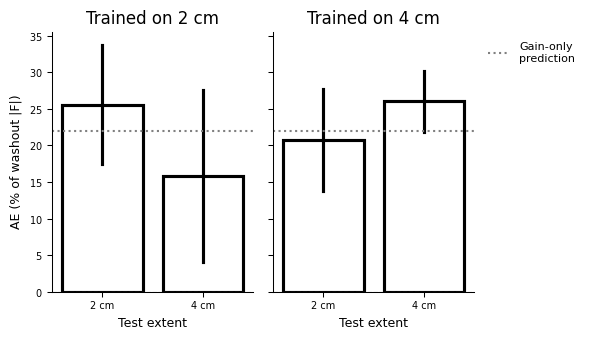

Scaling contrast: observed -2.3 %, gain predicts 0 %, additive predicts -11.7 %
Scaling contrast vs 0 (gain): p-value: 0.5554, t-stat: -0.62, df: 7
Scaling contrast vs additive prediction: p-value: 0.1336, t-stat: 1.70, df: 7
Local contrast: 7.5 %
Local contrast vs 0: p-value: 0.1357, t-stat: 1.69, df: 7


In [7]:
# --- Fig 2C: proportional AE (trained direction) ---
fig2_cells['test_label'] = fig2_cells['test_extent'].map({2: '2 cm', 4: '4 cm'})
test_order = ['2 cm', '4 cm']
gain_only_level = fig2_cells['AE_percent'].mean()

fig, axs = plt.subplots(1, 2, figsize=(6, 3.5), sharey=True)

for ax, train_ext in zip(axs, [2, 4]):
    sns.barplot(
        data=fig2_cells[fig2_cells['train_extent'] == train_ext],
        x='test_label',
        y='AE_percent',
        order=test_order,
        errorbar='se',
        legend=False,
        ax=ax,
        fill=False,
        color='black',
    )
    ax.axhline(gain_only_level, color='0.5', linestyle=':', linewidth=1.5)
    ax.axhline(0, color='gray', linestyle='--', linewidth=0.8)
    ax.set_title(f'Trained on {train_ext} cm')
    ax.set_xlabel('Test extent')
    ax.set_ylabel('AE (% of washout |F|)' if ax is axs[0] else '')
axs[-1].legend(
    handles=[Line2D([0], [0], color='0.5', linestyle=':', linewidth=1.5, label='Gain-only\nprediction')],
    frameon=False,
    bbox_to_anchor=(1.02, 1),
    loc='upper left',
)

sns.despine()
plt.tight_layout()
plt.savefig(path_figs + 'ae_fig2c_proportional_ae.pdf', bbox_inches='tight')
plt.show()

cells_wide = fig2_cells.pivot_table(index='subNum', columns=['train_extent', 'test_extent'], values='AE_percent')
scaling = ((cells_wide[(2, 4)] + cells_wide[(4, 4)]) - (cells_wide[(2, 2)] + cells_wide[(4, 2)])) / 2
local = ((cells_wide[(2, 2)] + cells_wide[(4, 4)]) - (cells_wide[(2, 4)] + cells_wide[(4, 2)])) / 2

# Additive prediction for the scaling contrast: each participant's mean AE (N) at their own washout forces
subj_mean_ae = fig2_cells.groupby('subNum')['AE'].mean()
subj_washout = fig2_cells.groupby(['subNum', 'test_extent'])['Washout'].mean().unstack()
additive_scaling = 100 * subj_mean_ae * (1 / subj_washout[4] - 1 / subj_washout[2])

print(f"Scaling contrast: observed {scaling.mean():.1f} %, gain predicts 0 %, additive predicts {additive_scaling.mean():.1f} %")
report_ttest("Scaling contrast vs 0 (gain)", stats.ttest_1samp(scaling, 0))
report_ttest("Scaling contrast vs additive prediction", stats.ttest_rel(scaling, additive_scaling))
print(f"Local contrast: {local.mean():.1f} %")
report_ttest("Local contrast vs 0", stats.ttest_1samp(local, 0))

### 2D — Joint decomposition: additive + gain + local

One linear model fitted to the four trained-direction cells of all participants:

`AE = a + g · washout|F| + l · [test extent = trained extent]`

- `a`: additive reduction (N)
- `g`: gain, the fractional reduction of force. It is plotted as its contribution at the mean washout force, `g · mean|F|` (N), so all three terms share one axis.
- `l`: extra reduction at the trained extent (N)

Error bars = 95 % bootstrap CI (resampling participants). **Additive:** `a > 0`, `g ≈ 0`. **Gain:** `g > 0`, `a ≈ 0`.

With only two extents, additive and gain differ in whether the AE line passes through zero force (2B), which assumes the relationship stays linear down to 0.

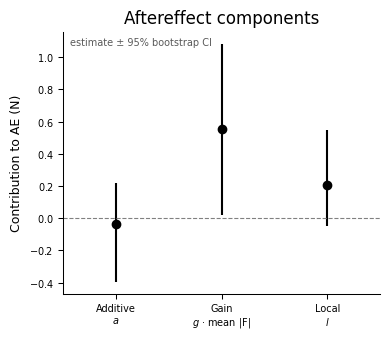

Additive a: -0.038 N [-0.398, 0.217]
Gain g · 2.84 N: 0.556 N [0.021, 1.080]
Local l: 0.206 N [-0.048, 0.547]
Gain g: 0.196 [0.007, 0.380] (fraction of washout force)


In [8]:
# --- Fig 2D: AE = a + g·W + l·[trained extent], bootstrap over participants ---
design = fig2_cells.assign(
    intercept=1.0,
    trained_extent=(fig2_cells['train_extent'] == fig2_cells['test_extent']).astype(float),
)
predictors = ['intercept', 'Washout', 'trained_extent']
X_by_subj = {s: g[predictors].to_numpy() for s, g in design.groupby('subNum')}
y_by_subj = {s: g['AE'].to_numpy() for s, g in design.groupby('subNum')}
subj_ids = np.array(list(X_by_subj))


def fit_components(subjects):
    X = np.vstack([X_by_subj[s] for s in subjects])
    y = np.concatenate([y_by_subj[s] for s in subjects])
    return np.linalg.lstsq(X, y, rcond=None)[0]


mean_washout = design['Washout'].mean()
to_newtons = np.array([1.0, mean_washout, 1.0])  # gain → contribution at the mean washout force

coef = fit_components(subj_ids)
boot = np.array([fit_components(rng.choice(subj_ids, len(subj_ids))) for _ in range(n_boot)])
estimate = coef * to_newtons
ci_low, ci_high = np.percentile(boot * to_newtons, [2.5, 97.5], axis=0)

component_labels = ['Additive\n$a$', 'Gain\n$g$ · mean |F|', 'Local\n$l$']

fig, ax = plt.subplots(figsize=(4, 3.5))
ax.errorbar(
    range(len(estimate)), estimate,
    yerr=[estimate - ci_low, ci_high - estimate],
    fmt='o', color='black', markersize=6, elinewidth=1.5, capsize=0,
)
ax.axhline(0, color='gray', linestyle='--', linewidth=0.8)
ax.set_xticks(range(len(estimate)))
ax.set_xticklabels(component_labels)
ax.set_xlim(-0.5, len(estimate) - 0.5)
ax.set_ylabel('Contribution to AE (N)')
ax.set_title('Aftereffect components')
ax.annotate(
    'estimate ± 95% bootstrap CI',
    xy=(0.02, 0.98),
    xycoords='axes fraction',
    va='top',
    ha='left',
    fontsize=7,
    color='0.35',
)

sns.despine()
plt.tight_layout()
plt.savefig(path_figs + 'ae_fig2d_components.pdf', bbox_inches='tight')
plt.show()

for label, est, lo, hi in zip(['Additive a', f'Gain g · {mean_washout:.2f} N', 'Local l'], estimate, ci_low, ci_high):
    print(f"{label}: {est:.3f} N [{lo:.3f}, {hi:.3f}]")
g_ci = np.percentile(boot[:, 1], [2.5, 97.5])
print(f"Gain g: {coef[1]:.3f} [{g_ci[0]:.3f}, {g_ci[1]:.3f}] (fraction of washout force)")

**Reading (n = 8).** The two panels of the original extent plot are not in conflict. Together they look like **gain + local**:

- Washout forces are compressed (4 cm ≈ 1.7 × the force of 2 cm), so gain predicts an AE ratio of ≈ 1.6–1.7, not 2. The observed ratio is ≈ 1.5; additive predicts 1.
- Averaged over trained extents, AE lies on the gain line through the origin (RMS error ≈ 0.02 N), not on the flat additive line (≈ 0.13 N).
- In proportional units AE is about the same at both extents on average (scaling ≈ −2 %; gain predicts 0 %, additive ≈ −12 %), with a crossover favouring whichever extent was trained (local ≈ +8 %). Neither contrast is significant at n = 8: this shows which way the evidence points, not yet a test.
- Fitted jointly, the additive term is ≈ 0 N, the gain term is ≈ 20 % of force (95 % CI excludes 0), and the local term is ≈ 0.2 N (CI just includes 0).

**Why training on 2 cm looks flat:** gain makes the AE larger at 4 cm while the local component makes it larger at 2 cm, and the two cancel. Trained on 4 cm, both push toward 4 cm.

## 3. Flexion vs extension

Flexion and extension use different muscle groups, so one reasonable expectation is **no transfer** between them.

- **3A:** Is there transfer, and what is its **sign**? Magnitude/gain predicts a positive opposite-direction AE (less force); a directional bias predicts a negative one (more force). Grey markers show each model's prediction, scaled to the observed trained-direction AE. Partial sharing lies anywhere between *Separate* and *Shared gain*.
- **3B:** Does transfer depend on which direction was trained?
- **3C:** The full generalization gradient, direction × extent, in proportional units.

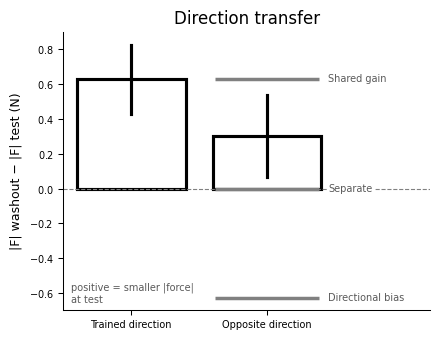

Opposite direction AE vs 0: p-value: 0.2411, t-stat: 1.28, df: 7
Trained vs opposite direction: p-value: 0.0108, t-stat: 3.44, df: 7
Opposite direction vs full directional bias (−trained AE): p-value: 0.0652, t-stat: 2.18, df: 7
Transfer ratio (opposite / trained): 0.48 [-0.41, 0.78] (95% bootstrap CI); separate = 0, shared = 1, directional < 0
Participants with a positive opposite-direction AE: 5/8


In [9]:
# --- Fig 3A: trained vs opposite direction, with model predictions ---
match_order = ['Trained direction', 'Opposite direction']
fig3_dir = pooled_aftereffect(ae_trials, ['direction_match'])
dir_wide = fig3_dir.pivot(index='subNum', columns='direction_match', values='AE')
trained_mean = dir_wide['Trained direction'].mean()

fig, ax = plt.subplots(figsize=(4.5, 3.5))
sns.barplot(
    data=fig3_dir,
    x='direction_match',
    y='AE',
    order=match_order,
    errorbar='se',
    legend=False,
    ax=ax,
    color='black',
    fill=False,
)
ax.axhline(0, color='gray', linestyle='--', linewidth=0.8)

model_levels = {'Shared gain': trained_mean, 'Separate': 0.0, 'Directional bias': -trained_mean}
for name, level in model_levels.items():
    ax.hlines(level, 0.62, 1.38, colors='0.5', linewidth=2.5, zorder=3)
    ax.text(1.45, level, name, va='center', ha='left', fontsize=7, color='0.35',
            bbox=dict(facecolor='white', edgecolor='none', pad=1))

ax.set_xlim(-0.5, 2.2)
ax.set_title('Direction transfer')
ax.set_xlabel('')
ax.set_ylabel('|F| washout − |F| test (N)')
ax.annotate(
    'positive = smaller |force|\nat test',
    xy=(0.02, 0.02),
    xycoords='axes fraction',
    va='bottom',
    ha='left',
    fontsize=7,
    color='0.35',
)

sns.despine()
plt.tight_layout()
plt.savefig(path_figs + 'ae_fig3a_direction_transfer.pdf', bbox_inches='tight')
plt.show()

trained_ae = dir_wide['Trained direction'].to_numpy()
opposite_ae = dir_wide['Opposite direction'].to_numpy()
report_ttest("Opposite direction AE vs 0", stats.ttest_1samp(opposite_ae, 0))
report_ttest("Trained vs opposite direction", stats.ttest_rel(trained_ae, opposite_ae))
report_ttest("Opposite direction vs full directional bias (−trained AE)", stats.ttest_rel(opposite_ae, -trained_ae))

boot_idx = rng.integers(0, len(trained_ae), size=(n_boot, len(trained_ae)))
boot_ratio = opposite_ae[boot_idx].mean(axis=1) / trained_ae[boot_idx].mean(axis=1)
ratio_ci = np.percentile(boot_ratio, [2.5, 97.5])
print(
    f"Transfer ratio (opposite / trained): {opposite_ae.mean() / trained_ae.mean():.2f} "
    f"[{ratio_ci[0]:.2f}, {ratio_ci[1]:.2f}] (95% bootstrap CI); "
    f"separate = 0, shared = 1, directional < 0"
)
print(f"Participants with a positive opposite-direction AE: {(opposite_ae > 0).sum()}/{n_subj}")

### 3B — Transfer by trained direction

x = trained direction; colour = test direction (flexion blue, extension vermillion). In each group, the bar matching the x label is the trained direction and the other bar is the transfer.

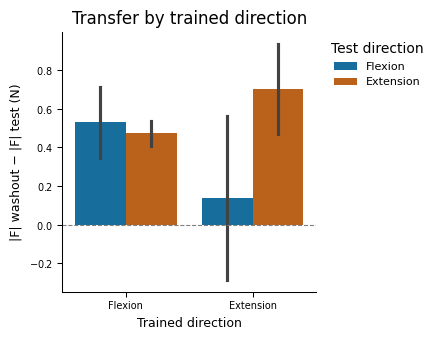

Flexion → extension transfer vs 0: p-value: 0.0002, t-stat: 7.28, df: 7
Extension → flexion transfer vs 0: p-value: 0.7545, t-stat: 0.33, df: 7
Flexion → extension vs extension → flexion: p-value: 0.4211, t-stat: 0.85, df: 7
Extension → flexion AE per participant (N): [-0.84, 1.99, -0.54, 1.18, -1.87, 0.36, 0.39, 0.42]


In [10]:
# --- Fig 3B: AE split by trained and tested direction ---
direction_order = ['Flexion', 'Extension']
fig3_split = pooled_aftereffect(ae_trials, ['train_direction', 'test_direction'])

fig, ax = plt.subplots(figsize=(4.5, 3.5))
sns.barplot(
    data=fig3_split,
    x='train_direction',
    y='AE',
    order=direction_order,
    hue='test_direction',
    hue_order=direction_order,
    palette=direction_palette,
    errorbar='se',
    ax=ax,
)
ax.axhline(0, color='gray', linestyle='--', linewidth=0.8)
ax.set_title('Transfer by trained direction')
ax.set_xlabel('Trained direction')
ax.set_ylabel('|F| washout − |F| test (N)')
ax.legend(title='Test direction', frameon=False, bbox_to_anchor=(1.02, 1), loc='upper left')

sns.despine()
plt.tight_layout()
plt.savefig(path_figs + 'ae_fig3b_transfer_by_direction.pdf', bbox_inches='tight')
plt.show()

split_wide = fig3_split.pivot_table(index='subNum', columns=['train_direction', 'test_direction'], values='AE')
flex_to_ext = split_wide[('Flexion', 'Extension')]
ext_to_flex = split_wide[('Extension', 'Flexion')]
report_ttest("Flexion → extension transfer vs 0", stats.ttest_1samp(flex_to_ext, 0))
report_ttest("Extension → flexion transfer vs 0", stats.ttest_1samp(ext_to_flex, 0))
report_ttest("Flexion → extension vs extension → flexion", stats.ttest_rel(flex_to_ext, ext_to_flex))
print("Extension → flexion AE per participant (N):", ext_to_flex.round(2).tolist())

### 3C — Generalization gradient

Proportional AE for every relation between the trained and tested target. Fully local: only the first black bar. One fully shared gain: all four bars equal. Within-participant 2 × 2 contrasts: direction, extent, interaction.

The last line checks whether the **transferred** part is itself gain-like: in the opposite direction, gain predicts the same AE % at 2 and 4 cm.

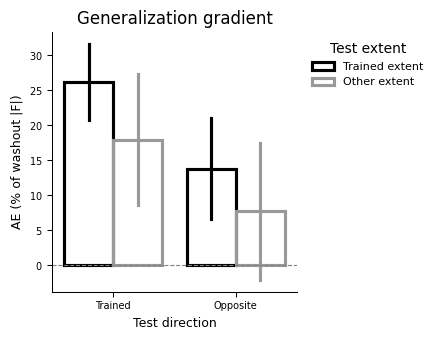

Direction (trained − opposite): p-value: 0.0064, t-stat: 3.83, df: 7
Extent (trained − other): p-value: 0.1531, t-stat: 1.60, df: 7
Direction × extent interaction: p-value: 0.5748, t-stat: 0.59, df: 7
Opposite direction: AE % at 4 cm vs 2 cm (0 under gain): p-value: 0.5775, t-stat: 0.58, df: 7


In [11]:
# --- Fig 3C: generalization gradient (AE %) ---
extent_match_order = ['Trained extent', 'Other extent']
extent_match_palette = {'Trained extent': 'black', 'Other extent': '0.6'}
fig3_grad = pooled_aftereffect(ae_trials, ['direction_match', 'extent_match'])

fig, ax = plt.subplots(figsize=(4.5, 3.5))
sns.barplot(
    data=fig3_grad,
    x='direction_match',
    y='AE_percent',
    order=match_order,
    hue='extent_match',
    hue_order=extent_match_order,
    palette=extent_match_palette,
    errorbar='se',
    fill=False,
    ax=ax,
)
ax.axhline(0, color='gray', linestyle='--', linewidth=0.8)
ax.set_title('Generalization gradient')
ax.set_xlabel('Test direction')
ax.set_xticks(range(len(match_order)))
ax.set_xticklabels(['Trained', 'Opposite'])
ax.set_ylabel('AE (% of washout |F|)')
ax.legend(title='Test extent', frameon=False, bbox_to_anchor=(1.02, 1), loc='upper left')

sns.despine()
plt.tight_layout()
plt.savefig(path_figs + 'ae_fig3c_generalization_gradient.pdf', bbox_inches='tight')
plt.show()

grad_wide = fig3_grad.pivot_table(index='subNum', columns=['direction_match', 'extent_match'], values='AE_percent')
tt, to = grad_wide[('Trained direction', 'Trained extent')], grad_wide[('Trained direction', 'Other extent')]
ot, oo = grad_wide[('Opposite direction', 'Trained extent')], grad_wide[('Opposite direction', 'Other extent')]
report_ttest("Direction (trained − opposite)", stats.ttest_1samp(((tt + to) - (ot + oo)) / 2, 0))
report_ttest("Extent (trained − other)", stats.ttest_1samp(((tt + ot) - (to + oo)) / 2, 0))
report_ttest("Direction × extent interaction", stats.ttest_1samp((tt - to) - (ot - oo), 0))

opp_extent = pooled_aftereffect(
    ae_trials.loc[ae_trials['direction_match'] == 'Opposite direction'], ['test_extent']
).pivot(index='subNum', columns='test_extent', values='AE_percent')
report_ttest("Opposite direction: AE % at 4 cm vs 2 cm (0 under gain)", stats.ttest_rel(opp_extent[4], opp_extent[2]))

**Reading (n = 8).**

- **Sign:** the opposite-direction AE is positive, meaning less force, not more. That matches a magnitude/gain change. With the whole test block it is not significantly different from 0, and only marginally different from the full directional-bias prediction (−1 × trained AE, p ≈ 0.07). In early test trials it is significantly positive, which excludes a directional bias.
- **Amount:** transfer is about half the trained-direction AE, and significantly smaller. So flexion and extension are neither separate nor one fully shared controller: they look **partially shared**.
- **Reliability:** with the whole test block, transfer is not yet reliably above 0 and its bootstrap CI is wide; with early test trials it is (Section 4).
- **Gradient:** proportional AE falls off along both dimensions (trained direction > opposite; trained extent > other extent). Only the direction step is reliable at n = 8.
- **By direction:** flexion → extension transfer is consistent across participants and nearly as large as the trained-direction AE. Extension → flexion is very variable, so there is no evidence yet for an asymmetry. Extension targets lose force at test after *any* training, which is also what a generic no-cursor undershoot on extension would look like (see caveats).

## 4. Robustness — the aftereffect decays during test

With no cursor at test, |F| drifts back toward washout, so averaging all 15 test trials dilutes the aftereffect.

- **4A:** Trial-by-trial AE % across the whole test block, for the trained vs opposite direction. The shaded area is the early window; dashed lines are group-average linear trends.
- **4B:** Key effects recomputed with only the first `n_early_trials` test trials per target, next to the whole block. The early window was chosen **after** seeing the drift, so treat it as a sensitivity check, not the primary test.

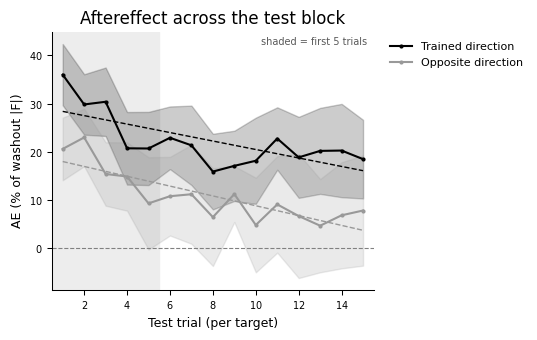

Trained direction: mean slope = -0.88 %/trial
  Trained direction slope vs 0: p-value: 0.0609, t-stat: -2.23, df: 7
Opposite direction: mean slope = -1.02 %/trial
  Opposite direction slope vs 0: p-value: 0.1478, t-stat: -1.63, df: 7


In [12]:
# --- Fig 4A: AE % across test trials (whole block) ---
full_block = prepare_aftereffect_trials(subjs_correct, n_test=15)
washout_ref = (
    full_block.loc[full_block['epoch'] == 'Washout']
    .groupby(['subNum', 'direction_match'])['force_magnitude'].mean()
    .rename('washout_force')
    .reset_index()
)
decay = (
    full_block.loc[full_block['epoch'] == 'Test']
    .groupby(['subNum', 'direction_match', 'trial_num_within_condition'])['force_magnitude'].mean()
    .reset_index()
    .merge(washout_ref, on=['subNum', 'direction_match'])
)
decay['AE_percent'] = 100 * (decay['washout_force'] - decay['force_magnitude']) / decay['washout_force']

fit_rows = []
for (sub, match), g in decay.groupby(['subNum', 'direction_match']):
    fit = stats.linregress(g['trial_num_within_condition'], g['AE_percent'])
    fit_rows.append({'subNum': sub, 'direction_match': match, 'slope': fit.slope, 'intercept': fit.intercept})
decay_fits = pd.DataFrame(fit_rows)

match_palette = {'Trained direction': 'black', 'Opposite direction': '0.6'}
n_te = int(decay['trial_num_within_condition'].max())
trial_x = np.arange(1, n_te + 1)

fig, ax = plt.subplots(figsize=(5.5, 3.5))
ax.axvspan(0.5, n_early_trials + 0.5, color='0.93', zorder=0)
sns.lineplot(
    data=decay,
    x='trial_num_within_condition',
    y='AE_percent',
    hue='direction_match',
    hue_order=match_order,
    palette=match_palette,
    errorbar='se',
    marker='o',
    markersize=3,
    markeredgewidth=0,
    ax=ax,
)
for match in match_order:
    f = decay_fits[decay_fits['direction_match'] == match]
    ax.plot(trial_x, f['intercept'].mean() + f['slope'].mean() * trial_x,
            color=match_palette[match], linestyle='--', linewidth=1.0)
ax.axhline(0, color='gray', linestyle='--', linewidth=0.8)
ax.set_xlim(0.5, n_te + 0.5)
ax.set_xlabel('Test trial (per target)')
ax.set_ylabel('AE (% of washout |F|)')
ax.set_title('Aftereffect across the test block')
ax.legend(title='', frameon=False, bbox_to_anchor=(1.02, 1), loc='upper left')
ax.annotate(
    f'shaded = first {n_early_trials} trials',
    xy=(0.98, 0.98),
    xycoords='axes fraction',
    va='top',
    ha='right',
    fontsize=7,
    color='0.35',
)

sns.despine()
plt.tight_layout()
plt.savefig(path_figs + 'ae_fig4a_test_decay.pdf', bbox_inches='tight')
plt.show()

for match in match_order:
    slopes = decay_fits.loc[decay_fits['direction_match'] == match, 'slope']
    print(f"{match}: mean slope = {slopes.mean():.2f} %/trial")
    report_ttest(f"  {match} slope vs 0", stats.ttest_1samp(slopes, 0))

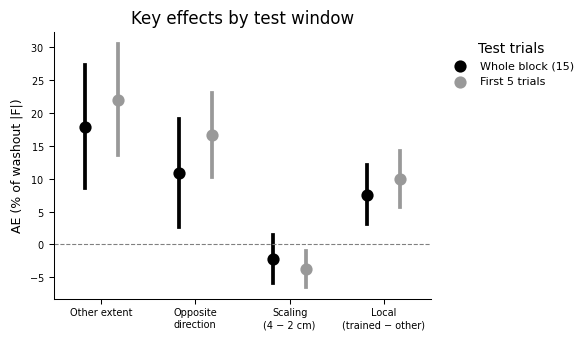

,test window,effect,mean (%),SEM (%),t,p (vs 0)
0,Whole block (15),Other extent,17.918,9.350,1.916,0.097
1,First 5 trials,Other extent,21.992,8.409,2.615,0.035
2,Whole block (15),Opposite direction,10.917,8.224,1.327,0.226
3,First 5 trials,Opposite direction,16.605,6.409,2.591,0.036
4,Whole block (15),Scaling (4 − 2 cm),-2.266,3.660,-0.619,0.555
5,First 5 trials,Scaling (4 − 2 cm),-3.668,2.740,-1.339,0.222
6,Whole block (15),Local (trained − other),7.550,4.478,1.686,0.136
7,First 5 trials,Local (trained − other),9.937,4.260,2.333,0.052


In [13]:
# --- Fig 4B: key effects, whole block vs early test trials ---
def key_effects(trials):
    """Per-participant key effects, all as AE % of washout |F|."""
    gen = pooled_aftereffect(trials, ['generalization']).pivot(
        index='subNum', columns='generalization', values='AE_percent'
    )
    same = pooled_aftereffect(
        trials.loc[trials['direction_match'] == 'Trained direction'], ['train_extent', 'test_extent']
    )
    cells = same.pivot_table(index='subNum', columns=['train_extent', 'test_extent'], values='AE_percent')
    return pd.DataFrame({
        'Other extent': gen['Other extent'],
        'Opposite\ndirection': gen['Opposite direction'],
        'Scaling\n(4 − 2 cm)': ((cells[(2, 4)] + cells[(4, 4)]) - (cells[(2, 2)] + cells[(4, 2)])) / 2,
        'Local\n(trained − other)': ((cells[(2, 2)] + cells[(4, 4)]) - (cells[(2, 4)] + cells[(4, 2)])) / 2,
    })


windows = {'Whole block (15)': 15, f'First {n_early_trials} trials': n_early_trials}
effects = (
    pd.concat([
        key_effects(prepare_aftereffect_trials(subjs_correct, n)).assign(window=label)
        for label, n in windows.items()
    ])
    .reset_index()
    .melt(id_vars=['subNum', 'window'], var_name='effect', value_name='AE_percent')
)
effect_order = list(key_effects(ae_trials).columns)
window_palette = dict(zip(windows, ['black', '0.6']))

fig, ax = plt.subplots(figsize=(6, 3.5))
sns.pointplot(
    data=effects,
    x='effect',
    y='AE_percent',
    order=effect_order,
    hue='window',
    hue_order=list(windows),
    palette=window_palette,
    errorbar='se',
    dodge=0.35,
    linestyle='none',
    ax=ax,
)
ax.axhline(0, color='gray', linestyle='--', linewidth=0.8)
ax.set_xlabel('')
ax.set_ylabel('AE (% of washout |F|)')
ax.set_title('Key effects by test window')
ax.legend(title='Test trials', frameon=False, bbox_to_anchor=(1.02, 1), loc='upper left')

sns.despine()
plt.tight_layout()
plt.savefig(path_figs + 'ae_fig4b_test_window.pdf', bbox_inches='tight')
plt.show()

summary_rows = []
for (window, effect), g in effects.groupby(['window', 'effect'], sort=False):
    result = stats.ttest_1samp(g['AE_percent'], 0)
    summary_rows.append({
        'test window': window,
        'effect': effect.replace('\n', ' '),
        'mean (%)': g['AE_percent'].mean(),
        'SEM (%)': g['AE_percent'].sem(),
        't': result.statistic,
        'p (vs 0)': result.pvalue,
    })
pd.DataFrame(summary_rows).round(3)

**Reading (n = 8).** Both the trained- and opposite-direction aftereffects decay over the test block at similar rates. That fits the transferred part being adaptation that washes out rather than a stable offset. In the early window the transfer and local effects grow: other-extent and opposite-direction transfer become significant, and the local component approaches significance. The scaling contrast stays small (gain-consistent).

## 5. The story so far (n = 8 of 20 planned)

1. **Not local.** The aftereffect peaks at the trained target but spreads to the other extent in the same direction, and partly to the opposite direction (Fig 1).
2. **Gain with a local component, not additive.** The seemingly mixed extent pattern is what **gain + local** predicts:
   - the right baseline is washout force, and 4 cm ≈ 1.7 × 2 cm (2A);
   - averaged over trained extents, AE falls on the gain line through the origin, not the additive flat line (2B);
   - proportional AE is flat across extents on average and crosses over toward the trained extent (2C);
   - a joint fit gives additive ≈ 0, gain ≈ 20 % of force, and local ≈ 0.2 N (2D).

   Trained on 2 cm, gain (→ larger at 4 cm) and local (→ larger at 2 cm) cancel, so the AE looks flat.
3. **Flexion ↔ extension: partial transfer of a magnitude change.** The opposite-direction AE has the gain sign (less force), not the directional-bias sign (more force). It is roughly half the trained-direction AE, so the two directions look **partially shared**: neither separate nor a single controller (3A–C). The transfer is reliable against 0 only in early test trials.
4. **Robust to the test-phase decay.** Conclusions hold, and get stronger, in early test trials (4A–B).

**Caveats**

- **Power.** n = 8: several contrasts are trends, and the transfer-ratio CI is wide with the whole test block.
- **No no-cursor baseline.** Test has no cursor and washout does, so any generic no-feedback change in |F| adds to every cell. This mainly limits the transfer claims (other extent, opposite direction), whose AEs are small. A no-cursor block before adaptation, or no-cursor probe trials in washout, would measure it directly and could be added for the remaining participants.
- **Two extents only.** Additive vs gain rests on the AE line extrapolating to 0 at zero force. A third extent would test proportionality directly.
- **Post hoc window.** The early-trial window was chosen after seeing the drift.